# Path Smoothing and Local Planning

This notebook introduces two important planning concepts for autonomous
driving:

1. Path smoothing
2. Local planning and obstacle avoidance

The previous planning experiment generated a collision-free path using
A* on a discrete occupancy grid.

The resulting path is valid for the grid environment, but it consists
of discrete horizontal and vertical movements. Such a path is not
necessarily suitable as a directly executable vehicle trajectory.

Path smoothing is therefore used to reduce unnecessary sharp changes
in the path geometry.

Local planning addresses a different problem. Instead of planning through
the complete known environment from the start to the goal, a local planner
reacts to nearby obstacles and changing conditions around the vehicle.

The experiments in this notebook use simplified two-dimensional examples
to demonstrate these concepts.

In [30]:
# 1-15D — Environment and Library Setup

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Environment setup complete.")

NumPy version: 2.4.6
Environment setup complete.


## Planning Environment

The planning environment is represented using the same type of occupancy
grid used in the previous A* experiment.

A value of:

- `0` represents a free cell
- `1` represents an obstacle

The start and goal positions are kept consistent with the global planning
example so that the relationship between global planning and path
smoothing can be observed directly.

In [31]:
# 2-15D — Create the Planning Environment

grid = np.zeros((15, 20), dtype=int)

# Define the same obstacle structure used in the A* example
grid[3:12, 8] = 1
grid[3, 8:15] = 1
grid[11, 8:15] = 1

start = (1, 2)
goal = (13, 17)

print("Grid shape:", grid.shape)
print("Obstacle cells:", np.sum(grid == 1))
print("Start:", start)
print("Goal:", goal)

Grid shape: (15, 20)
Obstacle cells: 21
Start: (1, 2)
Goal: (13, 17)


## Generate a Global Path

The global path is generated using the same A* concept introduced
previously.

For this experiment, the A* implementation is kept inside this notebook
so that the path-smoothing experiment can be reproduced independently.

The planner uses four-connected movement and a Manhattan-distance
heuristic.

In [32]:
# 3-15D — Define A* Helper Functions

import heapq


def heuristic(node, goal):
    """Manhattan-distance heuristic."""
    return abs(node[0] - goal[0]) + abs(node[1] - goal[1])


def get_neighbors(node, grid):
    """Return valid four-connected free neighbours."""
    row, col = node

    candidates = [
        (row - 1, col),
        (row + 1, col),
        (row, col - 1),
        (row, col + 1),
    ]

    neighbors = []

    for r, c in candidates:
        if 0 <= r < grid.shape[0] and 0 <= c < grid.shape[1]:
            if grid[r, c] == 0:
                neighbors.append((r, c))

    return neighbors


def astar(grid, start, goal):
    """Find a minimum-cost path through the occupancy grid."""
    open_set = []
    heapq.heappush(open_set, (0, start))

    came_from = {}
    g_cost = {start: 0}

    while open_set:
        _, current = heapq.heappop(open_set)

        if current == goal:
            path = [current]

            while current in came_from:
                current = came_from[current]
                path.append(current)

            return path[::-1]

        for neighbor in get_neighbors(current, grid):
            tentative_g = g_cost[current] + 1

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g

                f_cost = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_set, (f_cost, neighbor))

    return None

In [33]:
# 4-15D — Generate the Global A* Path

global_path = astar(grid, start, goal)

if global_path is None:
    print("No global path found.")
else:
    print("Global path found.")
    print("Number of cells:", len(global_path))
    print("Path:")
    print(global_path)

Global path found.
Number of cells: 28
Path:
[(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (2, 17), (3, 17), (4, 17), (5, 17), (6, 17), (7, 17), (8, 17), (9, 17), (10, 17), (11, 17), (12, 17), (13, 17)]


## Visualize the Global Path

The global path is plotted over the occupancy grid.

Because the path is represented by discrete grid cells, the resulting
trajectory contains sharp horizontal and vertical changes in direction.

This is acceptable as a grid-search solution, but a real vehicle cannot
normally change its motion direction instantaneously at every grid corner.
This motivates path smoothing.

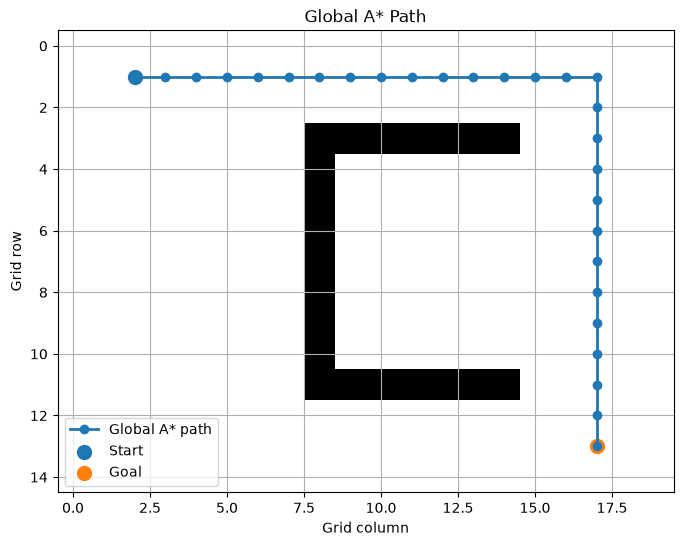

In [34]:
# 5-15D — Visualize the Global A* Path

path_array = np.array(global_path)

plt.figure(figsize=(10, 6))
plt.imshow(grid, cmap="gray_r", origin="upper")

plt.plot(
    path_array[:, 1],
    path_array[:, 0],
    marker="o",
    linewidth=2,
    label="Global A* path"
)

plt.scatter(start[1], start[0], s=100, label="Start")
plt.scatter(goal[1], goal[0], s=100, label="Goal")

plt.title("Global A* Path")
plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.legend()
plt.grid(True)
plt.show()

## Path Smoothing

A simple moving-average filter is used to demonstrate the basic idea of
path smoothing.

The filter replaces each interior point with an average of neighbouring
points.

This reduces abrupt point-to-point changes and produces a smoother
geometric representation.

This is intentionally a basic demonstration. A production autonomous
vehicle planner would require a smoothing method that also considers
vehicle kinematics, curvature, obstacle clearance, and other constraints.

In [35]:
# 6-15D — Apply Basic Path Smoothing

def smooth_path(path, window_size=3):
    """Smooth a path using a moving-average window."""
    path = np.asarray(path, dtype=float)

    smoothed = path.copy()
    half_window = window_size // 2

    for i in range(half_window, len(path) - half_window):
        smoothed[i] = np.mean(
            path[i - half_window:i + half_window + 1],
            axis=0
        )

    return smoothed


smoothed_path = smooth_path(global_path, window_size=3)

print("Original path points:", len(global_path))
print("Smoothed path points:", len(smoothed_path))
print("Start point:", smoothed_path[0])
print("Goal point:", smoothed_path[-1])

Original path points: 28
Smoothed path points: 28
Start point: [1. 2.]
Goal point: [13. 17.]


## Compare Global and Smoothed Paths

The original A* path and the smoothed path are shown together.

The purpose of this comparison is to observe the geometric effect of
smoothing rather than to claim that the smoothed path is automatically
safe or directly executable by a vehicle.

An important planning consideration is that smoothing can move a path
away from the original grid cells. Therefore, obstacle clearance must be
checked after smoothing.

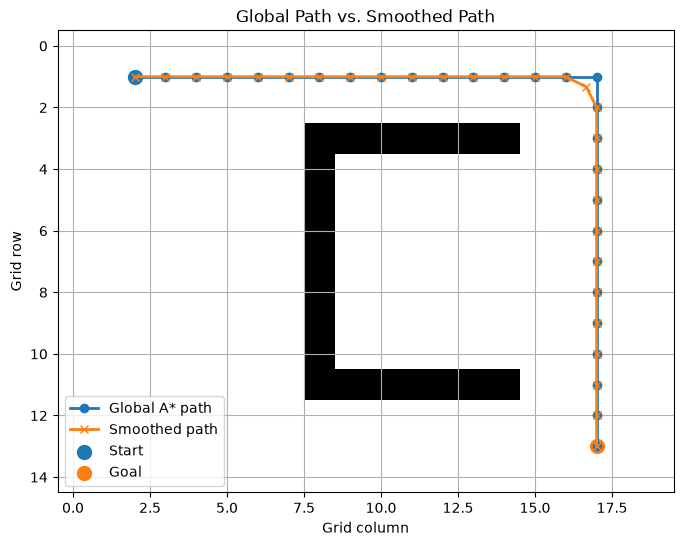

In [36]:
# 7-15D — Compare Original and Smoothed Paths

plt.figure(figsize=(10, 6))
plt.imshow(grid, cmap="gray_r", origin="upper")

global_array = np.asarray(global_path)

plt.plot(
    global_array[:, 1],
    global_array[:, 0],
    marker="o",
    linewidth=2,
    label="Global A* path"
)

plt.plot(
    smoothed_path[:, 1],
    smoothed_path[:, 0],
    marker="x",
    linewidth=2,
    label="Smoothed path"
)

plt.scatter(start[1], start[0], s=100, label="Start")
plt.scatter(goal[1], goal[0], s=100, label="Goal")

plt.title("Global Path vs. Smoothed Path")
plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.legend()
plt.grid(True)
plt.show()

## Smoothed Path Evaluation

A smoothed path should not be considered valid only because it looks
geometrically better.

The path should still remain reasonably separated from obstacles.

The following check evaluates each smoothed point by mapping it to the
nearest grid cell and checking whether that cell is occupied.

This is a simplified collision check. It does not account for vehicle
dimensions or the continuous path between sampled points.

In [37]:
# 8-15D — Validate the Smoothed Path

def validate_smoothed_path(smoothed_path, grid):
    """Check whether smoothed points fall inside free grid cells."""
    valid = True

    for point in smoothed_path:
        row = int(round(point[0]))
        col = int(round(point[1]))

        if not (0 <= row < grid.shape[0] and 0 <= col < grid.shape[1]):
            valid = False
            break

        if grid[row, col] == 1:
            valid = False
            break

    return valid


smoothed_path_valid = validate_smoothed_path(smoothed_path, grid)

print("Smoothed path remains within grid:", smoothed_path_valid)

Smoothed path remains within grid: True


# Local Planning

Global planning and local planning solve related but different problems.

A global planner determines a route through the broader known environment
from a start position to a goal position.

A local planner instead considers the vehicle's immediate surroundings.
It can modify or temporarily deviate from the global route when a nearby
obstacle makes the current route unsuitable.

In a real autonomous-driving system, local planning would typically use
current sensor observations together with the vehicle state and a
reference global path.

The following example demonstrates this concept using a simple local
obstacle placed directly on a reference path.

In [38]:
# 9-15D — Define a Local Planning Scenario

local_path = np.array([
    [7.0, 2.0],
    [7.0, 3.0],
    [7.0, 4.0],
    [7.0, 5.0],
    [7.0, 6.0],
    [7.0, 7.0],
    [7.0, 8.0],
    [7.0, 9.0],
    [7.0, 10.0],
    [7.0, 11.0],
    [7.0, 12.0],
])

# A nearby obstacle is introduced directly on the local reference path.
local_obstacle = np.array([7.0, 7.0])

print("Local reference path points:", len(local_path))
print("Local obstacle position:", local_obstacle)

Local reference path points: 11
Local obstacle position: [7. 7.]


## Visualize the Local Planning Problem

The local reference path passes through the newly introduced obstacle.

This represents a situation in which the global route may still be valid
at the larger environmental level, but a newly observed local obstacle
requires the vehicle to temporarily modify its path.

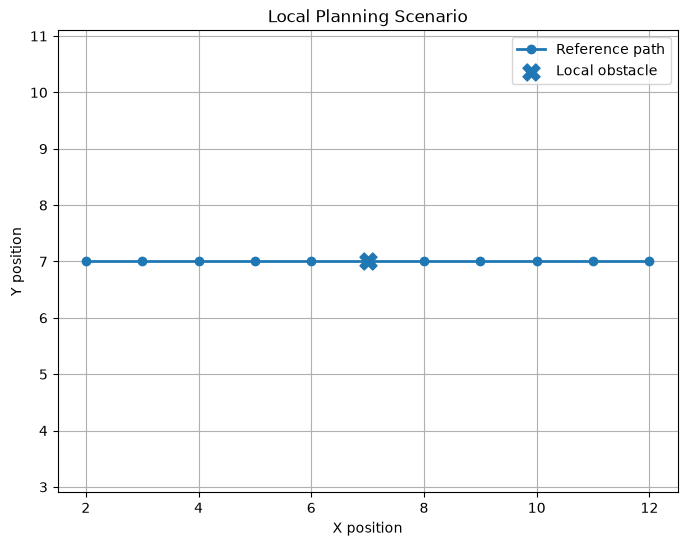

In [39]:
# 10-15D — Visualize the Local Planning Problem

plt.figure(figsize=(8, 6))

plt.plot(
    local_path[:, 1],
    local_path[:, 0],
    marker="o",
    linewidth=2,
    label="Reference path"
)

plt.scatter(
    local_obstacle[1],
    local_obstacle[0],
    s=150,
    marker="X",
    label="Local obstacle"
)

plt.title("Local Planning Scenario")
plt.xlabel("X position")
plt.ylabel("Y position")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

## Minimal Local Obstacle Avoidance

A simple local avoidance rule is used for demonstration.

When the reference path reaches the obstacle, the local planner inserts
a lateral offset around the obstacle before returning to the reference
path.

This is not a complete local planner. It is only intended to demonstrate
the principle that local planning can modify a global/reference path in
response to a nearby obstacle.

In [ ]:
# 11-15D — Implement Minimal Local Obstacle Avoidance

def create_local_avoidance_path(reference_path, obstacle, offset=2.0):
    """
    Create a simple local detour around a single obstacle.

    The reference path is modified only around the obstacle. The local
    path moves away from the reference line, passes the obstacle, and
    returns to the reference line.
    """
    reference_path = np.asarray(reference_path, dtype=float)
    obstacle = np.asarray(obstacle, dtype=float)

    distances = np.linalg.norm(reference_path - obstacle, axis=1)

    if np.min(distances) > 0:
        return reference_path.copy()

    obstacle_index = np.argmin(distances)

    # Keep the reference path before and after the obstacle.
    before = reference_path[:obstacle_index]
    after = reference_path[obstacle_index + 1:]

    # Create a clear detour above the obstacle.
    # Coordinates are [y, x], matching the reference-path representation.
    detour = np.array([
        [obstacle[0],     obstacle[1] - 1.0],
        [obstacle[0] + offset, obstacle[1] - 1.0],
        [obstacle[0] + offset, obstacle[1] + 1.0],
        [obstacle[0],     obstacle[1] + 1.0]
    ])

    local_avoidance_path = np.vstack([
        before,
        detour,
        after
    ])

    return local_avoidance_path


local_avoidance_path = create_local_avoidance_path(
    local_path,
    local_obstacle,
    offset=2.0
)

print("Local avoidance path generated.")
print("Reference path points:", len(local_path))
print("Local avoidance path points:", len(local_avoidance_path))

Local avoidance path generated.
Reference path points: 11
Local avoidance path points: 14


## Evaluate the Local Planner

The local avoidance path is compared with the original reference path.

The expected behaviour is:

Reference path
→ obstacle detected
→ temporary local deviation
→ return toward reference path

This illustrates the reactive nature of local planning.

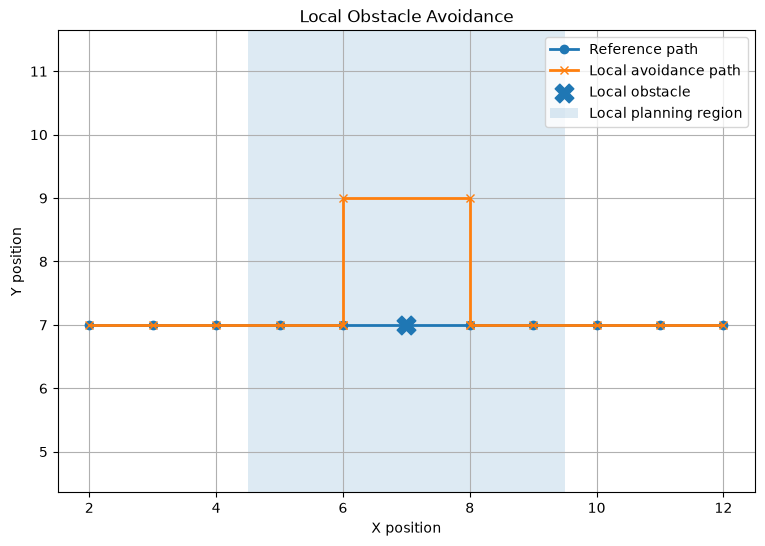

In [47]:
# 12-15D — Visualize Local Obstacle Avoidance

plt.figure(figsize=(9, 6))

plt.plot(
    local_path[:, 1],
    local_path[:, 0],
    marker="o",
    linewidth=2,
    label="Reference path"
)

plt.plot(
    local_avoidance_path[:, 1],
    local_avoidance_path[:, 0],
    marker="x",
    linewidth=2,
    label="Local avoidance path"
)

plt.scatter(
    local_obstacle[1],
    local_obstacle[0],
    s=180,
    marker="X",
    label="Local obstacle"
)

# Highlight the local avoidance region
obstacle_index = np.argmin(
    np.linalg.norm(local_path - local_obstacle, axis=1)
)

start_index = max(0, obstacle_index - 2)
end_index = min(len(local_path), obstacle_index + 3)

plt.axvspan(
    local_path[start_index, 1] - 0.5,
    local_path[end_index - 1, 1] + 0.5,
    alpha=0.15,
    label="Local planning region"
)

plt.title("Local Obstacle Avoidance")
plt.xlabel("X position")
plt.ylabel("Y position")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

## Global Planning vs. Local Planning

The experiments demonstrate the conceptual difference between the two
planning levels.

### Global Planning

The global planner:

- Considers the broader known environment
- Uses a start and goal position
- Produces a route through the environment
- Is typically planned less frequently
- Provides the overall route or reference path

The A* implementation from the previous experiment represents this level.

### Local Planning

The local planner:

- Considers the vehicle's nearby environment
- Reacts to newly observed obstacles
- Can temporarily modify the global/reference path
- Operates more frequently
- Produces a locally feasible motion or trajectory

In a complete autonomous-driving system, the global and local planners
work together rather than replacing one another.

Planning relationship:
Global route -> Local adaptation -> Vehicle motion

In [48]:
# 13-15D — Validate Local Avoidance Path

def calculate_minimum_obstacle_distance(path, obstacle):
    """Calculate the minimum distance between path points and an obstacle."""
    path = np.asarray(path, dtype=float)
    obstacle = np.asarray(obstacle, dtype=float)

    distances = np.linalg.norm(path - obstacle, axis=1)
    return np.min(distances)


minimum_distance = calculate_minimum_obstacle_distance(
    local_avoidance_path,
    local_obstacle
)

local_path_avoids_obstacle = minimum_distance > 0

print("Minimum path-point distance from obstacle:",
      round(minimum_distance, 2))
print("Local avoidance path avoids obstacle:",
      local_path_avoids_obstacle)

Minimum path-point distance from obstacle: 1.0
Local avoidance path avoids obstacle: True


## Final Evaluation

The experiments provide a basic demonstration of path smoothing and local
planning.

The A* path consists of discrete grid movements and therefore contains
sharp direction changes. The smoothing operation reduces these abrupt
changes and produces a more continuous geometric path.

The local-planning experiment demonstrates how a nearby obstacle can cause
a temporary deviation from a reference path.

However, neither implementation should be interpreted as a complete
vehicle trajectory planner.

A practical autonomous-driving planner would additionally consider:

- Vehicle dimensions
- Vehicle kinematics
- Steering limits
- Curvature
- Acceleration and braking limits
- Obstacle clearance
- Dynamic obstacles
- Sensor uncertainty
- Real-time replanning
- Prediction of other road users

These aspects are outside the scope of this minimal experiment.

In [50]:
# 14-15D — Summarize Planning Results

print("Path Planning Summary")
print("---------------------")
print("Global A* path cells:", len(global_path))
print("Smoothed path points:", len(smoothed_path))
print("Smoothed path valid:", smoothed_path_valid)
print("Local obstacle:", local_obstacle.tolist())
print("Minimum local path distance from obstacle:",
      round(minimum_distance, 2))
print("Local avoidance path avoids obstacle:",
      local_path_avoids_obstacle)

print("\nConcepts demonstrated:")
print("- Global path planning")
print("- Basic path smoothing")
print("- Smoothed-path validation")
print("- Local obstacle avoidance")
print("- Global vs. local planning")

Path Planning Summary
---------------------
Global A* path cells: 28
Smoothed path points: 28
Smoothed path valid: True
Local obstacle: [7.0, 7.0]
Minimum local path distance from obstacle: 1.0
Local avoidance path avoids obstacle: True

Concepts demonstrated:
- Global path planning
- Basic path smoothing
- Smoothed-path validation
- Local obstacle avoidance
- Global vs. local planning
